In [ ]:
import pathlib
import random
import re
import warnings

import alifedata_phyloinformatics_convert as apc
from hstrat import _auxiliary_lib as hstrat_aux
import iplotx as ipx
import marimo as mo
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from phyloframe import legacy as pfl
import polars as pl
from scipy import stats as scipy_stats
import seaborn as sns
from teeplot import teeplot as tp
from watermark import watermark

from pylib import osf_fetch, percentileofscore_grouped

warnings.filterwarnings("ignore", category=DeprecationWarning)
# Computer Modern math, e.g., for italic site class qualifiers
plt.rcParams["mathtext.fontset"] = "cm"

OSF_SLUG = "6pa9j"
NUM_SITES = 64
ALPHA = 0.05
NUM_CONTROL_SITES = 8
MAX_TREE_LEAVES = 4000
SEED = 1
# dark, middle, and light shades per site class; plots use the middle
ETI_PALETTE = {
    "MLS": ["#004C7A", "#0072B2", "#8FC3E6"],
    "BENwg": ["#00664F", "#009E73", "#8ED6BE"],
    "DELbg": ["#9A3F00", "#D55E00", "#F2B48A"],
    "neutral": ["#6E6E6E", "#A6A6A6", "#DADADA"],
}

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/alifedata_phyloinformatics_convert/_impl/phytrack_Systematcs.py:7: UserWarning: ImportWarning: phylotrackpy.Systematics import failed; inserting a no-op mock for Systematics. This is likely because phylotrackpy is not installed.
  warnings.warn(


In [ ]:
def gap_points(*artists):
    """Draw point-plot markers as gaps in their connecting lines, layered as:
    connecting line, white gap, error bar, white halo, then a small dot
    marking each position."""
    for artist in artists:
        if artist is None:
            continue
        for line in [*artist.get_lines()]:
            if line.get_marker() in ("None", None, ""):
                line.set_zorder(3)  # error bars (and reference lines)
                continue
            _is_axes = hasattr(artist, "plot")
            if not _is_axes:
                # legend entries: just a dot
                line.set_linestyle("none")
                line.set_markerfacecolor(line.get_color())
                line.set_markersize(7)
                line.set_markeredgewidth(0)
                continue
            # connecting line below a white gap
            line.set_zorder(1)
            if not len(line.get_xdata()):
                continue
            _xy = line.get_xdata(), line.get_ydata()
            artist.plot(
                *_xy,
                linestyle="none",
                marker="o",
                markersize=9,
                markeredgewidth=0,
                color="white",
                zorder=2,
            )
            line.set_marker("None")
            # white halo, then small dot, above the error bar
            for _size, _color, _z in (
                (3.6, "white", 4),
                (2.2, line.get_color(), 5),
            ):
                artist.plot(
                    *_xy,
                    linestyle="none",
                    marker="o",
                    markersize=_size,
                    markeredgewidth=0,
                    color=_color,
                    zorder=_z,
                )

In [ ]:
def effect_pct(effect):
    """Express an effect size label as a percent, passing "neu" through."""
    return (
        effect if effect in ("neu", "neutral") else f"{float(effect) * 100:g}"
    )

In [ ]:
def right_legend(g):
    """Replace a FacetGrid's legend with a single-column legend to the right
    of the panels, vertically centered on them."""
    _handles = [*g.legend.legend_handles]
    _labels = [_text.get_text() for _text in g.legend.get_texts()]
    g.legend.remove()
    g._legend = None
    g.tight_layout()
    _boxes = [_ax.get_position() for _ax in g.axes.flat]
    return g.figure.legend(
        _handles,
        _labels,
        loc="center left",
        bbox_to_anchor=(
            max(_b.x1 for _b in _boxes) + 0.02,
            (min(_b.y0 for _b in _boxes) + max(_b.y1 for _b in _boxes)) / 2,
        ),
        ncol=1,
        frameon=False,
        handlelength=0.8,
        handletextpad=0.5,
        labelspacing=1.0,
    )

In [ ]:
def corner_xlabel(g, legend, text="Effect\nSize (%)"):
    """Place the x axis label at bottom right, left-aligned under the legend
    and level with the bottom of the bottom-left panel's tick labels."""
    _renderer = g.figure.canvas.get_renderer()
    _to_fig = g.figure.transFigure.inverted()
    _ticks = [
        _t.get_window_extent(_renderer).transformed(_to_fig)
        for _t in g.axes.flat[-2].get_xticklabels()
    ]
    g.figure.text(
        legend.get_window_extent(_renderer).transformed(_to_fig).x0,
        min(_b.y0 for _b in _ticks),
        text,
        ha="left",
        va="bottom",
        fontsize=plt.rcParams["axes.labelsize"],
    )

In [ ]:
mo.md(f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
""")

```Text
Last updated: 2026-10-26T12:43:22.958003+00:00

Python implementation: CPython
Python version       : 3.10.22
IPython version      : 7.31.1

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 6.17.0-1022-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

seaborn                           : 0.13.2
numpy                             : 2.1.2
re                                : 2.2.1
teeplot                           : 1.4.2
polars                            : 1.36.1
scipy                             : 1.14.1
matplotlib                        : 3.10.9
hstrat                            : 1.25.2
iplotx                            : 1.8.0
pandas                            : 2.2.3
marimo                            : 0.23.2
alifedata_phyloinformatics_convert: 0.19.3
phyloframe                        : 0.12.2

```

In [ ]:
mo.md(f"""
# MLS Spectrum Subgrid Fossils: Detectability by Population Size and Effect Size

Applies the phylogeny-based multilevel selection (MLS) screen from *Extending a Phylogeny-based Method for Detecting Signatures of Multi-level Selection for Applications in Artificial Life* (ISAL 2025, <https://doi.org/10.1162/ISAL.a.916>; code at <https://github.com/mmore500/multilevel-selection-concept>) to wafer-scale evolution data, following `2026-10-15-mls-strong-fossils`.

Data were generated by [`wse-async-ga` `wsclust/2026-10-15-mls-spectrum-subgrid-fossils`](https://github.com/mmore500/wse-async-ga/tree/mlsnk-genome/wsclust/2026-10-15-mls-spectrum-subgrid-fossils) and are hosted at <https://osf.io/{OSF_SLUG}>.
That file is the minified hstrat-reconstructed phylogeny (`06-minify-phylo` output), holding one independently reconstructed tree per run.

Runs use genome flavor `genome_mlsspectrum_2026_10_15`, which carries eight MLS sites with effect sizes $s_i \\in [1.0, 0.5, 0.25, 0.1, 0.05, 0.025, 0.01, 0.005]$: carriers are clobbered as immigrants into an extinct tile population with probability $s_i$, but have within-population advantage $s'_i = (1 + s_i)^{{\\log_2(N) / 25}} - 1$.
The other 56 genome sites are neutral.
Site classes are labeled with ETI evaluation bar notation, giving each trait's between-group effect above and within-group effect below, and $\\varnothing$ for no effect: MLS $|^{{-}}_{{+}}$ and neutral sites NEU $|^{{\\varnothing}}_{{\\varnothing}}$.
Runs sweep subgrid size (27, 81, 243, and 0, i.e., the full grid), where subgrids are blocks of tiles between which migration is disabled.

Each subgrid is an isolated metapopulation, so populations are analyzed independently rather than pooled: within each population, the screen asks whether each MLS site

1. gives rise to more mutation-defined clades (MDCs) than expected for a neutral site (mutation-frequency screen), and
2. gives rise to MDCs that are smaller and/or shorter-lived than neutral-site MDCs (clade-fitness screen).

Detectability is the fraction of populations in which a screen is significant at $\\alpha = {ALPHA}$, broken down by population size and effect size.
As a null calibration, the same screens are applied to {NUM_CONTROL_SITES} randomly chosen neutral control sites.
""")

# MLS Spectrum Subgrid Fossils: Detectability by Population Size and Effect Size

Applies the phylogeny-based multilevel selection (MLS) screen from *Extending a Phylogeny-based Method for Detecting Signatures of Multi-level Selection for Applications in Artificial Life* (ISAL 2025, <https://doi.org/10.1162/ISAL.a.916>; code at <https://github.com/mmore500/multilevel-selection-concept>) to wafer-scale evolution data, following `2026-10-15-mls-strong-fossils`.

Data were generated by [`wse-async-ga` `wsclust/2026-10-15-mls-spectrum-subgrid-fossils`](https://github.com/mmore500/wse-async-ga/tree/mlsnk-genome/wsclust/2026-10-15-mls-spectrum-subgrid-fossils) and are hosted at <https://osf.io/6pa9j>.
That file is the minified hstrat-reconstructed phylogeny (`06-minify-phylo` output), holding one independently reconstructed tree per run.

Runs use genome flavor `genome_mlsspectrum_2026_10_15`, which carries eight MLS sites with effect sizes $s_i \in [1.0, 0.5, 0.25, 0.1, 0.05, 0.025, 0.01, 0.005]$: carriers are clobbered as immigrants into an extinct tile population with probability $s_i$, but have within-population advantage $s'_i = (1 + s_i)^{\log_2(N) / 25} - 1$.
The other 56 genome sites are neutral.
Site classes are labeled with ETI evaluation bar notation, giving each trait's between-group effect above and within-group effect below, and $\varnothing$ for no effect: MLS $|^{-}_{+}$ and neutral sites NEU $|^{\varnothing}_{\varnothing}$.
Runs sweep subgrid size (27, 81, 243, and 0, i.e., the full grid), where subgrids are blocks of tiles between which migration is disabled.

Each subgrid is an isolated metapopulation, so populations are analyzed independently rather than pooled: within each population, the screen asks whether each MLS site

1. gives rise to more mutation-defined clades (MDCs) than expected for a neutral site (mutation-frequency screen), and
2. gives rise to MDCs that are smaller and/or shorter-lived than neutral-site MDCs (clade-fitness screen).

Detectability is the fraction of populations in which a screen is significant at $\alpha = 0.05$, broken down by population size and effect size.
As a null calibration, the same screens are applied to 8 randomly chosen neutral control sites.

## Get Data

In [ ]:
data_path = osf_fetch(OSF_SLUG)

downloading https://osf.io/6pa9j/download -> /tmp/6pa9j
size: 87656218 bytes


In [ ]:
pl.scan_parquet(data_path).collect_schema()

Schema([('origin_time', Int16), ('dstream_rank', Int16), ('dstream_S', Int16), ('hstrat_differentia_bitwidth', UInt8), ('is_extant', Boolean), ('trait_focal', UInt32), ('layer', UInt8), ('layer_T', UInt8), ('row', UInt16), ('col', UInt16), ('subgrid', UInt16), ('subgrid_row', UInt8), ('subgrid_col', UInt8), ('config', String), ('file', Categorical), ('replicate', Categorical), ('sample_per_stratum', UInt32), ('genomeFlavor', Categorical), ('populationFlavor', Categorical), ('memcpyMajor', Categorical), ('globalSeed', UInt8), ('nCol', UInt16), ('nRow', UInt16), ('nWav', UInt8), ('nTrait', UInt8), ('nCycle', UInt16), ('nColSubgrid', UInt8), ('nRowSubgrid', UInt8), ('nonBlock', Boolean), ('tilePopSize', UInt16), ('tournSize', Float32), ('msec', Float32), ('tsc', UInt8), ('dstream_algo', Categorical), ('dstream_storage_bitoffset', UInt8), ('dstream_storage_bitwidth', UInt8), ('dstream_T_bitoffset', UInt8), ('dstream_T_bitwidth', UInt8), ('dstream_S_right', UInt8), ('flag_site_bitwidth', UInt8), ('flag_sites_bitoffset', UInt8), ('flag_sites_bitwidth', UInt8), ('mls_clobber_p_byte3_bit0', Float32), ('mls_selection_p_byte3_bit0', Float32), ('mls_clobber_p_byte3_bit1', Float32), ('mls_selection_p_byte3_bit1', Float32), ('mls_clobber_p_byte3_bit2', Float32), ('mls_selection_p_byte3_bit2', Float32), ('mls_clobber_p_byte3_bit3', Float32), ('mls_selection_p_byte3_bit3', Float32), ('mls_clobber_p_byte3_bit4', Float32), ('mls_selection_p_byte3_bit4', Float32), ('mls_clobber_p_byte3_bit5', Float32), ('mls_selection_p_byte3_bit5', Float32), ('mls_clobber_p_byte3_bit6', Float32), ('mls_selection_p_byte3_bit6', Float32), ('mls_clobber_p_byte3_bit7', Float32), ('mls_selection_p_byte3_bit7', Float32), ('_compconf_dummy', UInt8), ('CEREBRASLIB_TRAITLOGGER_NUM_BITS', UInt16), ('CEREBRASLIB_NONZERO_FIT_FUDGE', Float32), ('CEREBRASLIB_CLOBBER_IMMIGRANT_P', Float32), ('CEREBRASLIB_POPULATION_EXTINCTION_PROBABILITY', Float32), ('CEREBRASLIB_TRAITLOGGER_DILATION', UInt8), ('CEREBRASLIB_TRAITLOGGER_DSTREAM_ALGO_NAME', Categorical), ('CEREBRASLIB_HSTRAT_T_DILATION', UInt8), ('CEREBRASLIB_HSTRAT_DSTREAM_ALGO_NAME', Categorical), ('ASYNC_GA_GENOME_FLAVOR', Categorical), ('ASYNC_GA_POPULATION_FLAVOR', Categorical), ('ASYNC_GA_POPSIZE', UInt16), ('clade_size', UInt8), ('last_origin_time', Int16), ('trait_present', UInt64), ('ancestor_offset', Int16)])

In [ ]:
_lazy = pl.scan_parquet(data_path)
_schema = _lazy.collect_schema()
_config_cols = [
    name
    for name in _schema.names()
    if name.startswith(("ASYNC_GA_", "CEREBRASLIB_", "dstream_algo"))
    or re.match(r"^mls_(clobber|selection)_p_byte\d+_bit\d+$", name)
    or name
    in (
        "config",
        "genomeFlavor",
        "populationFlavor",
        "globalSeed",
        "nCol",
        "nRow",
        "nColSubgrid",
        "nRowSubgrid",
        "nWav",
        "nTrait",
        "nCycle",
        "tilePopSize",
        "tournSize",
        "replicate",
        "trait_focal",
        "dstream_S",
        "hstrat_differentia_bitwidth",
    )
]
config_df = (
    _lazy.filter(pl.col("clade_size") > 0)
    .select(_config_cols)
    .unique()
    .sort("nRowSubgrid")
    .collect()
)
assert config_df["config"].is_unique().all(), "expected one row per run"
assert (config_df["nRowSubgrid"] == config_df["nColSubgrid"]).all()
config_df.transpose(include_header=True)

column,column_0,column_1,column_2,column_3
str,str,str,str,str
"""dstream_S""","""128""","""128""","""128""","""128"""
"""hstrat_differentia_bitwidth""","""1""","""1""","""1""","""1"""
"""trait_focal""","""4278190080""","""4278190080""","""4278190080""","""4278190080"""
"""config""","""flavor=genome_mlsspectrum_2026…","""flavor=genome_mlsspectrum_2026…","""flavor=genome_mlsspectrum_2026…","""flavor=genome_mlsspectrum_2026…"
"""replicate""","""4fe4fef4-ae95-41d2-9ef7-13d4aa…","""53c9659f-5969-45ee-be8c-10d2ea…","""94fbc1e9-139b-4739-8fda-b6af10…","""acfc690a-9488-419e-a189-5fd0d0…"
…,…,…,…,…
"""CEREBRASLIB_HSTRAT_T_DILATION""","""1""","""1""","""1""","""1"""
"""CEREBRASLIB_HSTRAT_DSTREAM_ALG…","""hybrid_0_steady_1_tilted_2_alg…","""hybrid_0_steady_1_tilted_2_alg…","""hybrid_0_steady_1_tilted_2_alg…","""hybrid_0_steady_1_tilted_2_alg…"
"""ASYNC_GA_GENOME_FLAVOR""","""genome_mlsspectrum_2026_10_15""","""genome_mlsspectrum_2026_10_15""","""genome_mlsspectrum_2026_10_15""","""genome_mlsspectrum_2026_10_15"""


In [ ]:
# MLS site i is flag byte B, bit b (trait site 8B + b); its clobber
# probability is effect size s_i (CEREBRASLIB_CLOBBER_IMMIGRANT_P = 1.0)
_site_cols = [
    (int(B) * 8 + int(b), what, col)
    for col in config_df.columns
    for what, B, b in re.findall(
        r"^mls_(clobber|selection)_p_byte(\d+)_bit(\d+)$", col
    )
]
effect_sizes = (
    pd.DataFrame(
        [
            {
                "config": row["config"],
                "site": site,
                f"{what}_p": row[col],
            }
            for row in config_df.iter_rows(named=True)
            for site, what, col in _site_cols
        ],
    )
    .groupby(["config", "site"], as_index=False)
    .first()
    .merge(config_df.select("config", "tilePopSize").to_pandas())
)
# effect sizes are the same across runs
assert (effect_sizes.groupby("site")["clobber_p"].nunique() == 1).all()
effect_sizes = effect_sizes.rename(columns={"clobber_p": "effect_size"})
focal_sites = sorted(effect_sizes["site"].unique().tolist())
_focal_mask = sum(1 << site for site in focal_sites)
assert (config_df["trait_focal"] == _focal_mask).all(), "focal mismatch"
background_sites = [
    site for site in range(NUM_SITES) if site not in focal_sites
]
control_sites = sorted(
    np.random.default_rng(SEED)
    .choice(background_sites, NUM_CONTROL_SITES, replace=False)
    .tolist()
)
site_effect_sizes = effect_sizes.groupby("site")["effect_size"].first()
# ETI evaluation bar notation: between-group effect above, within-group
# effect below, with null (crossed circle) for no effect
kind_labels = {
    "MLS": r"MLS$|^{-}_{+}$",
    "DELbg": r"DEL$\mathit{bg}|^{-}_{\varnothing}$",
    "BENwg": r"BEN$\mathit{wg}|^{\varnothing}_{+}$",
    "NEU": r"NEU$|^{\varnothing}_{\varnothing}$",
}
site_labels = pd.Series(
    {
        site: (
            f"{kind_labels['MLS']} s={site_effect_sizes[site]:g}"
            if site in focal_sites
            else kind_labels["NEU"]
        )
        for site in range(NUM_SITES)
    },
)
mutation_order = [
    f"{kind_labels['MLS']} s={_s:g}"
    for _s in sorted(site_effect_sizes.unique(), reverse=True)
] + [kind_labels["NEU"]]
effect_sizes

,config,site,effect_size,selection_p,tilePopSize
0,flavor=genome_mlsspectrum_2026_10_15+subgrid=0+seed=1,24,1.000,0.248331,256
1,flavor=genome_mlsspectrum_2026_10_15+subgrid=0+seed=1,25,0.500,0.138542,256
2,flavor=genome_mlsspectrum_2026_10_15+subgrid=0+seed=1,26,0.250,0.074017,256
3,flavor=genome_mlsspectrum_2026_10_15+subgrid=0+seed=1,27,0.100,0.030969,256
4,flavor=genome_mlsspectrum_2026_10_15+subgrid=0+seed=1,28,0.050,0.015735,256
...,...,...,...,...,...
27,flavor=genome_mlsspectrum_2026_10_15+subgrid=81+seed=3,27,0.100,0.030969,256
28,flavor=genome_mlsspectrum_2026_10_15+subgrid=81+seed=3,28,0.050,0.015735,256
29,flavor=genome_mlsspectrum_2026_10_15+subgrid=81+seed=3,29,0.025,0.007933,256
30,flavor=genome_mlsspectrum_2026_10_15+subgrid=81+seed=3,30,0.010,0.003189,256


In [ ]:
_df = pl.read_parquet(
    data_path,
    columns=[
        "ancestor_offset",
        "origin_time",
        "last_origin_time",
        "clade_size",
        "trait_present",
        "config",
        "layer",
        "subgrid",
    ],
)
# unminify: rows are in depth-first order, with id = row index
phylo_raw = (
    _df.with_row_index("id")
    .with_columns(
        pl.col("id").cast(pl.Int64),
        ancestor_id=(
            pl.col("id").cast(pl.Int64)
            - pl.col("ancestor_offset").cast(pl.Int64)
        ),
        config=pl.col("config").cast(pl.String),
    )
    .drop("ancestor_offset")
    .to_pandas()
)
del _df
# some roots lack origin_time; roots can be no later than the run start
_no_time = phylo_raw["origin_time"].isna()
assert (
    phylo_raw.loc[_no_time, "ancestor_id"] == phylo_raw.loc[_no_time, "id"]
).all()
phylo_raw["origin_time"] = phylo_raw["origin_time"].fillna(-1)
phylo_raw["last_origin_time"] = phylo_raw["last_origin_time"].fillna(
    phylo_raw["origin_time"]
)
phylo_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11238846 entries, 0 to 11238845
Data columns (total 9 columns):
 #   Column            Dtype  
---  ------            -----  
 0   id                int64  
 1   origin_time       float64
 2   last_origin_time  float64
 3   clade_size        uint8  
 4   trait_present     float64
 5   config            object 
 6   layer             float64
 7   subgrid           float64
 8   ancestor_id       int64  
dtypes: float64(5), int64(2), object(1), uint8(1)
memory usage: 696.7+ MB


In [ ]:
_is_genome = phylo_raw["clade_size"] > 0
assert (_is_genome == phylo_raw["trait_present"].notna()).all()
assert (_is_genome == phylo_raw["subgrid"].notna()).all()
assert phylo_raw["config"].notna().all()
assert (phylo_raw["ancestor_id"] <= phylo_raw["id"]).all()
_has_child = np.zeros(len(phylo_raw), dtype=bool)
_has_child[phylo_raw["ancestor_id"]] = True
_has_child[phylo_raw["ancestor_id"] == phylo_raw["id"]] = False
# collapsed monomorphic clades and fossil genomes are leaves
assert not (_has_child & _is_genome).any()
"ok"

'ok'

## Prep Data

Minification collapsed each maximal clade of genomes sharing identical traits onto its root, which became a leaf; `clade_size` gives the number of fossil genomes it represents, and `last_origin_time` the latest among them.
Genome counts below weight leaves by `clade_size`.

Fossil layer 0 samples the initial population, at `origin_time == -1` before any lineage history accumulated (as in `2026-10-15-mls-strong-fossils`), so these genomes are dropped (collapsed leaves are kept if any member has `last_origin_time >= 0`).
Some roots have no `origin_time`; as roots can be no later than the run start, it is set to -1.
Lineages without retained leaves are pruned and unifurcations collapsed.

In [ ]:
_tips = phylo_raw[phylo_raw["clade_size"] > 0]
_tips.groupby("config").agg(
    num_leaves=("id", "size"),
    num_genomes=("clade_size", "sum"),
    clade_size_mean=("clade_size", "mean"),
    clade_size_max=("clade_size", "max"),
    num_layers=("layer", "nunique"),
    origin_time_min=("origin_time", "min"),
    last_origin_time_max=("last_origin_time", "max"),
    negative_origin_frac=("last_origin_time", lambda x: (x < 0).mean()),
).T

config,flavor=genome_mlsspectrum_2026_10_15+subgrid=0+seed=1,flavor=genome_mlsspectrum_2026_10_15+subgrid=243+seed=4,flavor=genome_mlsspectrum_2026_10_15+subgrid=27+seed=2,flavor=genome_mlsspectrum_2026_10_15+subgrid=81+seed=3
num_leaves,1.415278e+06,1.644695e+06,2.029146e+06,1.882578e+06
num_genomes,2.268688e+06,3.148898e+06,3.938019e+06,3.636803e+06
clade_size_mean,1.602998e+00,1.914579e+00,1.940727e+00,1.931821e+00
clade_size_max,7.400000e+01,7.500000e+01,9.700000e+01,1.020000e+02
num_layers,3.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00
origin_time_min,-1.000000e+00,-1.000000e+00,-1.000000e+00,-1.000000e+00
last_origin_time_max,2.631000e+03,2.747000e+03,2.701000e+03,2.671000e+03
negative_origin_frac,5.926821e-01,3.088342e-01,3.122028e-01,3.124253e-01


In [ ]:
phylo_raw.assign(is_genome=phylo_raw["clade_size"] > 0).groupby(
    "is_genome"
)[["origin_time", "last_origin_time"]].describe().T.assign(
    dtype=str(phylo_raw["origin_time"].dtype),
)

is_genome False True dtype origin_time count 4.267149e+06 6.971697e+06 float64 mean 7.801759e+02 7.378139e+02 float64 std 5.820058e+02 7.395199e+02 float64 min -1.000000e+00 -1.000000e+00 float64 25% 2.630000e+02 -1.000000e+00 float64 ... ... ... ... ... last_origin_time min -1.000000e+00 -1.000000e+00 float64 25% 2.630000e+02 -1.000000e+00 float64 50% 7.430000e+02 6.070000e+02 float64 75% 1.214000e+03 1.603000e+03 float64 max 2.639000e+03 2.747000e+03 float64 16 rows × 3 columns

In [ ]:
phylo_pruned = (
    phylo_raw.assign(
        extant=(phylo_raw["clade_size"] > 0)
        & (phylo_raw["last_origin_time"] >= 0),
    )
    .pipe(pfl.alifestd_to_working_format)
    .pipe(pfl.alifestd_prune_extinct_lineages_asexual, mutate=True)
    .pipe(pfl.alifestd_collapse_unifurcations, mutate=True)
    .pipe(pfl.alifestd_to_working_format, mutate=True)
    .pipe(pfl.alifestd_mark_leaves, mutate=True)
    .reset_index(drop=True)
)
assert (phylo_pruned["is_leaf"] == phylo_pruned["extant"]).all()

## Split Populations

Subgrids share no migration, so no true common ancestry links genomes from different subgrids (or runs); each run's tree was reconstructed independently, but hstrat reconstruction can still join unrelated lineages at spurious deep nodes.
To analyze each population (run × subgrid) independently, nodes whose descendant leaves span more than one population are deleted, making each maximal single-population clade a root.
Each population's forest is then analyzed separately.

Edge subgrids are truncated by the grid boundary (e.g., 755 columns is not a multiple of 27), so only full-size subgrids are retained.

In [ ]:
_config_codes = {
    config: i for i, config in enumerate(config_df["config"].to_list())
}
_is_leaf = phylo_pruned["is_leaf"].to_numpy()
_pop_code = np.where(
    _is_leaf,
    phylo_pruned["config"].map(_config_codes).to_numpy(dtype=np.int64)
    * 2**32
    + phylo_pruned["subgrid"].fillna(0).to_numpy(dtype=np.int64),
    -1,
)
_pure = pfl.alifestd_mask_monomorphic_clades_asexual(
    phylo_pruned[["id", "ancestor_id"]],
    trait_mask=_is_leaf,
    trait_values=_pop_code,
)["alifestd_mask_monomorphic_clades_asexual"].to_numpy()
_ancestor_ids = phylo_pruned["ancestor_id"].to_numpy()
_is_root = _ancestor_ids == phylo_pruned["id"].to_numpy()
split_summary = pd.Series(
    {
        "num_nodes": len(phylo_pruned),
        "num_multipopulation_nodes": int((~_pure).sum()),
        "num_roots_before": int(_is_root.sum()),
        "num_roots_after": int(
            (_pure & (_is_root | ~_pure[_ancestor_ids])).sum()
        ),
    },
).to_frame("value")

phylo_split = (
    phylo_pruned.assign(
        ancestor_id=np.where(
            _pure[_ancestor_ids], _ancestor_ids, phylo_pruned["id"]
        ),
        pop_code=_pop_code,
    )[_pure]
    .pipe(pfl.alifestd_to_working_format, mutate=True)
    .pipe(pfl.alifestd_mark_roots, mutate=True)
    .pipe(pfl.alifestd_mark_root_id, mutate=True)
    .reset_index(drop=True)
)
_root_pops = (
    phylo_split.loc[phylo_split["is_leaf"]]
    .groupby("root_id")["pop_code"]
    .agg(["first", "nunique"])
)
assert (_root_pops["nunique"] == 1).all()
phylo_split["pop_code"] = phylo_split["root_id"].map(_root_pops["first"])
assert (phylo_split["pop_code"] >= 0).all()
phylo_split["config"] = phylo_split.groupby("pop_code")[
    "config"
].transform("first")
phylo_split["subgrid"] = (phylo_split["pop_code"] % 2**32).astype(int)
split_summary

,value
num_nodes,8670428
num_multipopulation_nodes,646354
num_roots_before,196694
num_roots_after,767013


In [ ]:
# cast grid dimensions from unsigned dtypes, which would wrap on the
# negation in the ceiling division below
_config = (
    config_df.select(
        "config",
        "nRow",
        "nCol",
        "nRowSubgrid",
        "nColSubgrid",
        "tilePopSize",
    )
    .to_pandas()
    .astype(
        {
            col: "int64"
            for col in (
                "nRow",
                "nCol",
                "nRowSubgrid",
                "nColSubgrid",
                "tilePopSize",
            )
        },
    )
)
_leaves = phylo_split[phylo_split["is_leaf"]]
populations = (
    _leaves.groupby("pop_code")
    .agg(
        config=("config", "first"),
        subgrid=("subgrid", "first"),
        num_leaves=("id", "size"),
        num_genomes=("clade_size", "sum"),
        num_roots=("root_id", "nunique"),
    )
    .reset_index()
    .merge(_config, on="config")
)
_has_subgrids = populations["nRowSubgrid"] > 0
_nrow_sub = populations["nRowSubgrid"].where(
    _has_subgrids, populations["nRow"]
)
_ncol_sub = populations["nColSubgrid"].where(
    _has_subgrids, populations["nCol"]
)
_nsub_cols = -(-populations["nCol"] // _ncol_sub)
_sub_row = populations["subgrid"] // _nsub_cols
_sub_col = populations["subgrid"] % _nsub_cols
populations["is_full_size"] = (
    (_sub_row + 1) * _nrow_sub <= populations["nRow"]
) & ((_sub_col + 1) * _ncol_sub <= populations["nCol"])
populations["pop_tiles"] = (_nrow_sub * _ncol_sub).astype(int)
populations["pop_size"] = [
    f"{r}x{c}"
    for r, c in zip(_nrow_sub.astype(int), _ncol_sub.astype(int))
]
pop_size_order = (
    populations.sort_values("pop_tiles")["pop_size"].unique().tolist()
)
populations.groupby(["pop_size", "is_full_size"], sort=False).agg(
    num_populations=("pop_code", "size"),
    pop_tiles=("pop_tiles", "first"),
    tile_pop_size=("tilePopSize", "first"),
    num_leaves_median=("num_leaves", "median"),
    num_genomes_median=("num_genomes", "median"),
    num_genomes_min=("num_genomes", "min"),
    num_genomes_max=("num_genomes", "max"),
    num_roots_median=("num_roots", "median"),
).T

pop_size 1170x755 27x27 81x81 243x243 is_full_size True True False True False True False num_populations 1.0 1161.0 71.0 126.0 24.0 12.0 8.0 pop_tiles 883350.0 729.0 729.0 6561.0 6561.0 59049.0 59049.0 tile_pop_size 256.0 256.0 256.0 256.0 256.0 256.0 256.0 num_leaves_median 576468.0 1149.0 1093.0 9537.5 3569.5 72591.0 10645.0 num_genomes_median 1385338.0 2703.0 2653.0 22273.0 8362.5 167052.5 25110.5 num_genomes_min 1385338.0 2582.0 896.0 21895.0 3681.0 166653.0 20295.0 num_genomes_max 1385338.0 2866.0 2751.0 22677.0 11658.0 167665.0 168116.0 num_roots_median 2058.0 213.0 197.0 1935.0 666.0 16155.0 1944.0

In [ ]:
_full_pops = populations.loc[populations["is_full_size"], "pop_code"]
phylo = (
    phylo_split[phylo_split["pop_code"].isin(_full_pops)]
    .pipe(pfl.alifestd_to_working_format)
    .pipe(pfl.alifestd_mark_roots, mutate=True)
    .pipe(pfl.alifestd_mark_root_id, mutate=True)
    .pipe(pfl.alifestd_mark_num_leaves_asexual, mutate=True)
    .reset_index(drop=True)
)
phylo["trait_present"] = (
    phylo["trait_present"].fillna(0).to_numpy(dtype=np.uint64)
)
_is_leaf = phylo["is_leaf"].to_numpy()
phylo["num_genomes"] = pfl.alifestd_calc_clade_trait_count_asexual(
    phylo[["id", "ancestor_id"]],
    # passing counts rather than a mask sums genomes over descendants
    trait_mask=np.where(_is_leaf, phylo["clade_size"], 0),
)
# collapsed leaves' clades last until their latest member genome
phylo["max_descendant_origin_time"] = (
    phylo[["id", "ancestor_id"]]
    .assign(
        origin_time=np.where(
            _is_leaf, phylo["last_origin_time"], phylo["origin_time"]
        ),
    )
    .pipe(pfl.alifestd_mark_max_descendant_origin_time_asexual)[
        "max_descendant_origin_time"
    ]
    .to_numpy()
)
phylo = phylo.pipe(pfl.alifestd_mark_clade_duration_asexual, mutate=True)
phylo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7267656 entries, 0 to 7267655
Data columns (total 18 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   id                          int64  
 1   origin_time                 float64
 2   last_origin_time            float64
 3   clade_size                  uint8  
 4   trait_present               uint64 
 5   config                      object 
 6   layer                       float64
 7   subgrid                     int64  
 8   ancestor_id                 int64  
 9   extant                      bool   
 10  is_leaf                     bool   
 11  pop_code                    int64  
 12  is_root                     bool   
 13  root_id                     int64  
 14  num_leaves                  int64  
 15  num_genomes                 int64  
 16  max_descendant_origin_time  float64
 17  clade_duration              float64
dtypes: bool(3), float64(5), int64(7), object(1), uint64(1), uint8(

In [ ]:
_bad = ~(phylo["clade_duration"] >= 0)
phylo.loc[
    _bad,
    [
        "id",
        "ancestor_id",
        "is_leaf",
        "origin_time",
        "last_origin_time",
        "max_descendant_origin_time",
        "clade_duration",
        "clade_size",
        "pop_code",
    ],
].describe(include="all").T.assign(num_bad=int(_bad.sum()))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max,num_bad
id,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
ancestor_id,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
is_leaf,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
origin_time,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
last_origin_time,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
max_descendant_origin_time,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
clade_duration,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
clade_size,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
pop_code,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


In [ ]:
mo.md(f"""
## Example Phylogenies

Radial tree drawings in the style of the reference work's wafer-scale figure, one per population size.
For each, a population is sampled at random and its largest tree with at most {MAX_TREE_LEAVES} leaves is drawn.
Diamonds mark tips carrying any MLS (focal) mutation; circles mark tips carrying any neutral (background) mutation.
""")

## Example Phylogenies

Radial tree drawings in the style of the reference work's wafer-scale figure, one per population size.
For each, a population is sampled at random and its largest tree with at most 4000 leaves is drawn.
Diamonds mark tips carrying any MLS (focal) mutation; circles mark tips carrying any neutral (background) mutation.

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=27x27+root_id=2232373+viz=tree+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=27x27+root_id=2232373+viz=tree+ext=.png


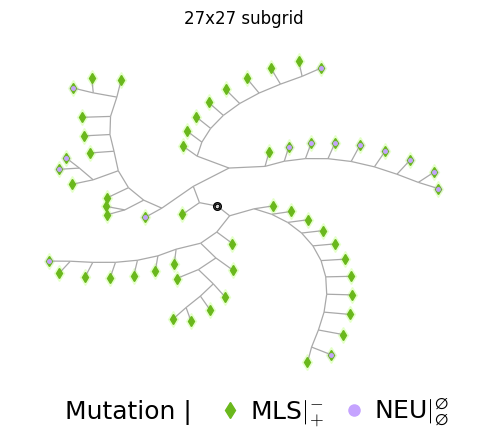

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=81x81+root_id=3880792+viz=tree+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=81x81+root_id=3880792+viz=tree+ext=.png


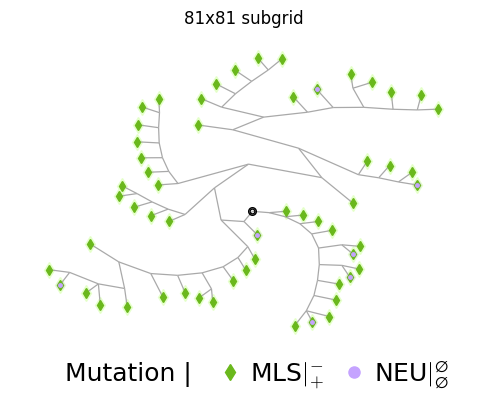

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=243x243+root_id=5072296+viz=tree+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=243x243+root_id=5072296+viz=tree+ext=.png


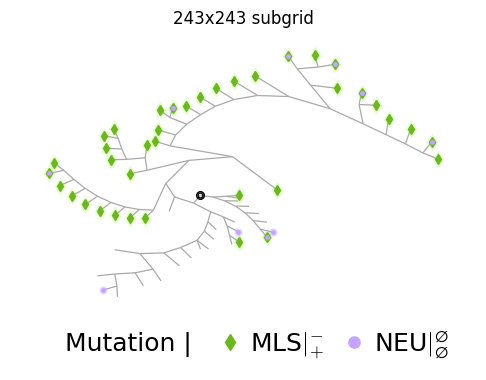

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=1170x755+root_id=6765781+viz=tree+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/edge-color=darkgray+layout=radial+pop_size=1170x755+root_id=6765781+viz=tree+ext=.png


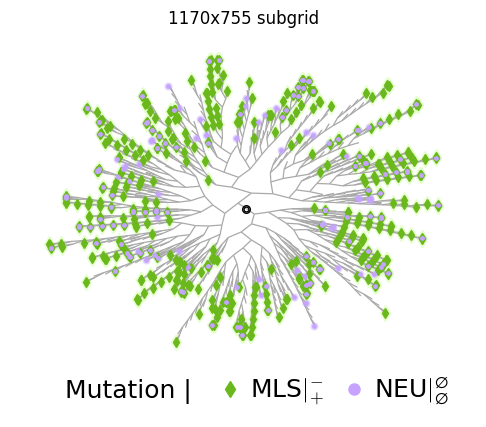

In [ ]:
_focal_mask = np.uint64(sum(1 << site for site in focal_sites))
_trait_present = phylo["trait_present"].to_numpy(dtype=np.uint64)
_is_leaf = phylo["is_leaf"].to_numpy()
_phylo = phylo.assign(
    has_mls=np.where(
        _is_leaf, (_trait_present & _focal_mask) != 0, np.nan
    ),
    has_neutral=np.where(
        _is_leaf, (_trait_present & ~_focal_mask) != 0, np.nan
    ),
)
_roots = _phylo.loc[_phylo["is_root"], ["id", "num_leaves", "pop_code"]]
_roots = _roots[_roots["num_leaves"] <= MAX_TREE_LEAVES]
_rng = random.Random(SEED)
for _pop_size in pop_size_order:
    _pops = populations.loc[
        populations["is_full_size"]
        & (populations["pop_size"] == _pop_size)
        & populations["pop_code"].isin(_roots["pop_code"]),
        "pop_code",
    ].tolist()
    if not _pops:
        continue
    _pop_code = _rng.choice(_pops)
    _root_id = (
        _roots.loc[_roots["pop_code"] == _pop_code]
        .nlargest(1, "num_leaves")["id"]
        .item()
    )

    _subtree = (
        _phylo[_phylo["root_id"] == _root_id]
        .pipe(pfl.alifestd_assign_contiguous_ids)
        .pipe(pfl.alifestd_try_add_ancestor_list_col)
    )
    _tree = apc.alife_dataframe_to_dendropy_tree(
        _subtree,
        setattrs=["has_mls", "has_neutral"],
    )
    with hstrat_aux.RngStateContext(6):
        _tree.ladderize()
        _tree.reorder(key=lambda *args: max(random.random(), 0.89))

    with tp.teed(
        ipx.plotting.tree,
        _tree,
        aspect=0.7,
        edge_color="darkgray",
        edge_linewidth=0.9,
        ladderize=True,
        layout="radial",
        layout_angular=True,
        layout_start=0.25,
        margins=0,
        teeplot_outattrs={"pop_size": _pop_size, "root_id": _root_id},
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _teed:
        plt.gcf().set_size_inches(6, 6)

        for _n, (_x, _y) in _teed.get_layout().T.items():
            _x_, _y_ = _x * np.cos(_y), _x * np.sin(_y)
            if _n.has_mls == 1.0:
                plt.plot(
                    _x_,
                    _y_,
                    "d",
                    markersize=8,
                    color="#E2FFC4",
                    alpha=0.8,
                    zorder=0,
                )
                plt.plot(
                    _x_,
                    _y_,
                    "d",
                    markersize=5,
                    color="#6AB81C",
                    alpha=1,
                    zorder=2,
                )
            if _n.has_neutral == 1.0:
                plt.plot(
                    _x_,
                    _y_,
                    "o",
                    markersize=5,
                    color="#C5A3FF",
                    alpha=0.3,
                    zorder=1,
                )
                plt.plot(
                    _x_,
                    _y_,
                    "o",
                    markersize=2.5,
                    color="#C5A3FF",
                    alpha=1.0,
                    zorder=3,
                )
            if _n is _tree.seed_node:
                for _size in 3.5, 5.5:
                    plt.plot(
                        _x_,
                        _y_,
                        "o",
                        markersize=_size,
                        color="black",
                        alpha=1,
                        fillstyle="none",
                    )

        plt.gca().margins(x=0.02, y=0.02)
        plt.title(f"{_pop_size} subgrid")

        (_h0,) = plt.plot(
            [], [], "d", markersize=0, color="#FFFFFF", label="Mutation | "
        )
        (_h1,) = plt.plot(
            [],
            [],
            "d",
            markersize=8,
            color="#6AB81C",
            label=r"MLS$|^{-}_{+}$",
        )
        (_h2,) = plt.plot(
            [],
            [],
            "o",
            markersize=8,
            color="#C5A3FF",
            label=r"NEU$|^{\varnothing}_{\varnothing}$",
        )
        plt.legend(
            handles=[_h0, _h1, _h2],
            loc="upper center",
            bbox_to_anchor=(0.48, 0.05),
            frameon=False,
            ncol=4,
            fontsize=18,
            columnspacing=0.2,
            handletextpad=-0.2,
        )
    plt.close("all")

## Screen Mutation-defined Clades

MDCs are identified for each of the 64 trait sites by Fitch maximum parsimony over leaf states (root state assumed absent), as in `2026-10-15-mls-strong-fossils`.
Because each population's trees share no nodes with other populations', one screen over the whole forest is equivalent to screening each population separately.

The screen uses phyloframe's `alifestd_screen_trait_defined_clades_fitch_asexual`, which requires phyloframe >= 0.12.2 to run in linear time at this data size.

MDC size is measured as `carriers`, the number of descendant fossil genomes carrying the mutation; `num_genomes` counts all descendant fossil genomes.
`carrier_frac` is the carrier fraction among descendant genomes, and `is_terminal` marks MDCs arising on a terminal branch to a single genome (MDC node is an uncollapsed leaf).
`clade_duration` spans from MDC origin to its latest descendant fossil.

In [ ]:
_work = phylo[["id", "ancestor_id"]].copy()
_is_leaf = phylo["is_leaf"].to_numpy()
_clade_size = phylo["clade_size"].fillna(0).to_numpy(dtype=np.int64)
_trait_present = phylo["trait_present"].to_numpy(dtype=np.uint64)
mdc_ids = {}
mdc_carriers = {}
for _site in mo.status.progress_bar(range(NUM_SITES)):
    _has = ((_trait_present >> np.uint64(_site)) & np.uint64(1)) != 0
    _mask = _work.pipe(
        pfl.alifestd_screen_trait_defined_clades_fitch_asexual,
        mutate=True,
        mask_trait_absent=_is_leaf & ~_has,
        mask_trait_present=_is_leaf & _has,
    ).astype(bool)
    # passing counts rather than a mask sums carriers over descendants
    _carriers = _work.pipe(
        pfl.alifestd_calc_clade_trait_count_asexual,
        mutate=True,
        trait_mask=np.where(_is_leaf & _has, _clade_size, 0),
    )
    mdc_ids[_site] = np.flatnonzero(_mask)
    mdc_carriers[_site] = _carriers[_mask]

In [ ]:
_cols = [
    "id",
    "origin_time",
    "num_genomes",
    "clade_duration",
    "is_leaf",
    "clade_size",
    "pop_code",
]
mdcs = pd.concat(
    [
        phylo.loc[ids, _cols].assign(
            site=site,
            is_focal=site in focal_sites,
            is_control=site in control_sites,
            carriers=mdc_carriers[site],
        )
        for site, ids in mdc_ids.items()
    ],
    ignore_index=True,
)
mdcs["is_terminal"] = mdcs["is_leaf"] & (mdcs["clade_size"] == 1)
mdcs["carrier_frac"] = mdcs["carriers"] / mdcs["num_genomes"]
mdcs["effect_size"] = mdcs["site"].map(site_effect_sizes)
mdcs["mutation"] = mdcs["site"].map(site_labels)
mdcs = mdcs.drop(columns=["is_leaf", "clade_size"]).merge(
    populations[["pop_code", "pop_size", "pop_tiles"]], on="pop_code"
)
mdcs.groupby(["pop_size", "mutation"], sort=False).agg(
    num_mdcs=("id", "size"),
    carriers_mean=("carriers", "mean"),
    carriers_singleton_frac=("carriers", lambda x: (x == 1).mean()),
    carrier_frac_mean=("carrier_frac", "mean"),
    terminal_frac=("is_terminal", "mean"),
    clade_duration_mean=("clade_duration", "mean"),
).unstack("pop_size")

num_mdcs carriers_mean carriers_singleton_frac ... carrier_frac_mean terminal_frac clade_duration_mean pop_size 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 ... 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 mutation NEU$|^{\varnothing}_{\varnothing}$ 121463 110404 85070 81765 3.224974 3.075187 2.911496 2.966905 0.637626 0.642187 ... 0.998373 0.998209 0.637626 0.642187 0.635818 0.563725 261.500292 260.874235 273.600964 297.323769 MLS$|^{-}_{+}$ s=1 73079 65553 47220 40492 1.146704 1.135265 1.109869 1.034427 0.872138 0.880722 ... 0.995362 0.990252 0.872138 0.880722 0.901059 0.968586 71.047113 66.993349 57.648136 29.268991 MLS$|^{-}_{+}$ s=0.5 46569 43396 34804 44818 10.251369 9.760623 8.912108 10.026083 0.335481 0.335423 ... 0.997444 0.992422 0.335481 0.335423 0.335938 0.234281 589.343061 595.174463 625.437191 786.491655 MLS$|^{-}_{+}$ s=0.25 25122 23749 19033 23923 9.800215 9.351804 8.374980 9.454458 0.355226 0.354962 ... 0.998420 0.994982 0.355226 0.354962 0.352756 0.263512 559.767932 567.838646 591.467977 723.570873 MLS$|^{-}_{+}$ s=0.1 9923 9177 7452 8837 8.259700 7.578729 6.948470 7.513975 0.418724 0.422905 ... 0.998731 0.997568 0.418724 0.422905 0.417606 0.308815 489.894286 487.312520 515.660762 619.728075 MLS$|^{-}_{+}$ s=0.05 5369 4869 3849 4435 7.086608 6.913124 6.105742 6.558061 0.473272 0.465188 ... 0.998414 0.996543 0.473272 0.465188 0.468953 0.374521 427.257031 441.844732 453.009873 551.887260 MLS$|^{-}_{+}$ s=0.025 3682 3420 2612 2882 6.569527 6.457018 6.010720 6.287300 0.519555 0.508772 ... 0.998646 0.998199 0.519555 0.508772 0.487749 0.397988 385.887833 402.320468 430.900459 513.671409 MLS$|^{-}_{+}$ s=0.01 2855 2587 2063 2267 6.490018 6.348280 5.653417 6.470225 0.542207 0.518361 ... 0.998688 0.997850 0.542207 0.518361 0.533204 0.408910 370.123292 392.739080 406.733398 507.060432 MLS$|^{-}_{+}$ s=0.005 2589 2531 1896 2025 5.978370 6.228763 5.212025 6.275556 0.537273 0.537337 ... 0.998621 0.996223 0.537273 0.537337 0.566983 0.422222 359.847045 373.474121 362.322785 500.856296 9 rows × 24 columns

## Mutation-frequency Screen

Within each population, baseline rate $\lambda$ is the mean MDC count per background (neutral) site.
Site significance is the Poisson survival probability of observing at least the site's MDC count under $\mathsf{Pois}(\lambda)$.
Neutral control sites are screened the same way, against the mean over the other background sites.
Populations with no background MDCs ($\lambda = 0$) are not screened.

In [ ]:
_pops = populations.loc[populations["is_full_size"], "pop_code"]
_counts = (
    mdcs.groupby(["pop_code", "site"])
    .size()
    .unstack("site")
    .reindex(index=_pops, columns=range(NUM_SITES))
    .fillna(0)
)
_bg_sum = _counts[background_sites].sum(axis=1)
_num_bg = len(background_sites)
_records = []
for _site in [*focal_sites, *control_sites]:
    _is_control = _site in control_sites
    _lam = (
        (_bg_sum - _counts[_site]) / (_num_bg - 1)
        if _is_control
        else _bg_sum / _num_bg
    )
    _k = _counts[_site]
    _records.append(
        pd.DataFrame(
            {
                "pop_code": _counts.index,
                "site": _site,
                "is_control": _is_control,
                "mdc_count": _k.to_numpy(),
                "lambda": _lam.to_numpy(),
                "fold_enrichment": (_k / _lam).to_numpy(),
                "poisson_sf_p": np.where(
                    _lam > 0, scipy_stats.poisson.sf(_k - 1, _lam), np.nan
                ),
            },
        ),
    )
freq_screen = pd.concat(_records, ignore_index=True).merge(
    populations[["pop_code", "pop_size", "pop_tiles"]], on="pop_code"
)
freq_screen["mutation"] = freq_screen["site"].map(site_labels)
freq_screen["detected"] = freq_screen["poisson_sf_p"] < ALPHA
freq_screen.groupby(["pop_size", "mutation"], sort=False).agg(
    num_populations=("pop_code", "nunique"),
    mdc_count_mean=("mdc_count", "mean"),
    lambda_mean=("lambda", "mean"),
    fold_enrichment_median=("fold_enrichment", "median"),
    detection_rate=("detected", "mean"),
).unstack("pop_size")

num_populations mdc_count_mean lambda_mean fold_enrichment_median detection_rate pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 mutation MLS$|^{-}_{+}$ s=1 1 1161 126 12 40492.00 62.944875 520.261905 3935.000000 1460.089286 1.868202 15.646825 126.592262 27.732551 33.703704 33.106692 31.067850 1.0 1.000000 1.000000 1.000000 MLS$|^{-}_{+}$ s=0.5 1 1161 126 12 44818.00 40.111111 344.412698 2900.333333 1460.089286 1.868202 15.646825 126.592262 30.695383 21.538462 22.051909 22.878334 1.0 1.000000 1.000000 1.000000 MLS$|^{-}_{+}$ s=0.25 1 1161 126 12 23923.00 21.638243 188.484127 1586.083333 1460.089286 1.868202 15.646825 126.592262 16.384614 11.603604 12.082032 12.423077 1.0 1.000000 1.000000 1.000000 MLS$|^{-}_{+}$ s=0.1 1 1161 126 12 8837.00 8.546942 72.833333 621.000000 1460.089286 1.868202 15.646825 126.592262 6.052370 4.480000 4.593951 4.940504 1.0 0.910422 1.000000 1.000000 MLS$|^{-}_{+}$ s=0.05 1 1161 126 12 4435.00 4.624462 38.642857 320.750000 1460.089286 1.868202 15.646825 126.592262 3.037485 2.352941 2.515147 2.543149 1.0 0.437554 0.992063 1.000000 MLS$|^{-}_{+}$ s=0.025 1 1161 126 12 2882.00 3.171404 27.142857 217.666667 1460.089286 1.868202 15.646825 126.592262 1.973852 1.615385 1.718709 1.680489 1.0 0.184324 0.793651 1.000000 MLS$|^{-}_{+}$ s=0.01 1 1161 126 12 2267.00 2.459087 20.531746 171.916667 1460.089286 1.868202 15.646825 126.592262 1.552645 1.154639 1.291811 1.358341 1.0 0.079242 0.293651 1.000000 MLS$|^{-}_{+}$ s=0.005 1 1161 126 12 2025.00 2.229974 20.087302 158.000000 1460.089286 1.868202 15.646825 126.592262 1.386901 1.108911 1.277813 1.242805 1.0 0.053402 0.277778 0.916667 NEU$|^{\varnothing}_{\varnothing}$ 1 1161 126 12 1431.75 1.862726 15.627976 127.593750 1460.604545 1.868301 15.647168 126.574053 0.974497 0.990991 0.981049 1.003911 0.0 0.033376 0.047619 0.093750

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/estimator=median+hue=pop-size+viz=pointplot+x=mutation+y=fold-enrichment+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/estimator=median+hue=pop-size+viz=pointplot+x=mutation+y=fold-enrichment+ext=.png


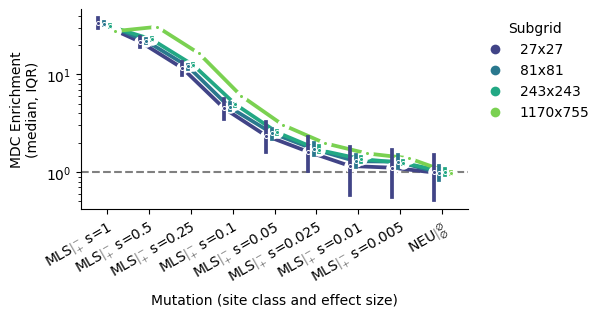

In [ ]:
with tp.teed(
    sns.pointplot,
    data=freq_screen.replace([np.inf, -np.inf], np.nan),
    x="mutation",
    y="fold_enrichment",
    order=mutation_order,
    hue="pop_size",
    hue_order=pop_size_order,
    palette="viridis",
    estimator="median",
    errorbar=("pi", 50),
    dodge=0.4,
    teeplot_outexclude=["palette", "hue_order", "dodge", "order"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _ax:
    gap_points(_ax, _ax.get_legend())
    _ax.axhline(1, color="gray", linestyle="--", zorder=0)
    _ax.set_yscale("log")
    _ax.set_xlabel("Mutation (site class and effect size)")
    _ax.set_ylabel("MDC Enrichment\n(median, IQR)")
    plt.setp(
        _ax.get_xticklabels(),
        rotation=30,
        ha="right",
        rotation_mode="anchor",
    )
    sns.move_legend(
        _ax,
        "upper left",
        bbox_to_anchor=(1, 1),
        title="Subgrid",
        frameon=False,
    )
    sns.despine(ax=_ax)
    _ax.figure.set_size_inches(5, 2.6)

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/hue=pop-size+viz=pointplot+x=mutation+y=detected+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/hue=pop-size+viz=pointplot+x=mutation+y=detected+ext=.png


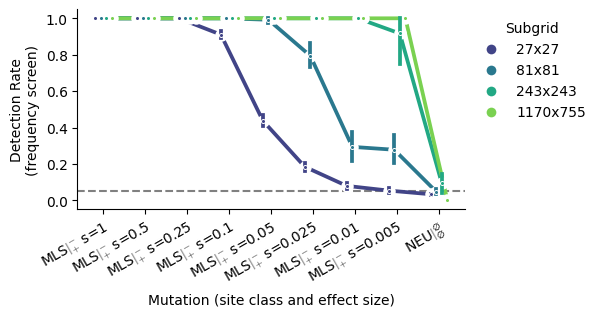

In [ ]:
with tp.teed(
    sns.pointplot,
    data=freq_screen.astype({"detected": float}),
    x="mutation",
    y="detected",
    order=mutation_order,
    hue="pop_size",
    hue_order=pop_size_order,
    palette="viridis",
    errorbar=("ci", 95),
    n_boot=1000,
    seed=SEED,
    dodge=0.4,
    teeplot_outexclude=["palette", "hue_order", "dodge", "order", "seed"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _ax:
    gap_points(_ax, _ax.get_legend())
    _ax.axhline(ALPHA, color="gray", linestyle="--", zorder=0)
    _ax.set_ylim(-0.05, 1.05)
    _ax.set_xlabel("Mutation (site class and effect size)")
    _ax.set_ylabel("Detection Rate\n(frequency screen)")
    plt.setp(
        _ax.get_xticklabels(),
        rotation=30,
        ha="right",
        rotation_mode="anchor",
    )
    sns.move_legend(
        _ax,
        "upper left",
        bbox_to_anchor=(1, 1),
        title="Subgrid",
        frameon=False,
    )
    sns.despine(ax=_ax)
    _ax.figure.set_size_inches(5, 2.6)

## Clade-fitness Screen

Within each population, each MDC's size (`carriers`) and clade duration are percentile-ranked (mean rank for ties) against comparator MDCs: the pooled MDCs of background (neutral) sites in the same population, drawn from the same MDC subset.
Under the `epoch100` normalization, comparison is further restricted to comparators originating within the same 100-update `origin_time` bin, controlling for recency bias.

For each population and site, a one-sided Mann-Whitney U test asks whether the site's MDC percentiles are lower than those of background MDCs (excluding the site itself, for neutral control sites).
MLS predicts lower percentiles.

MDC subsets are `all` MDCs, `inner` (excluding terminal-branch MDCs), and `inner_f75` (non-terminal MDCs with at least 75% carriers).

In [ ]:
subsets = {
    "all": lambda df: np.ones(len(df), dtype=bool),
    "inner": lambda df: ~df["is_terminal"].to_numpy(),
    "inner_f75": lambda df: (
        ~df["is_terminal"].to_numpy()
        & (df["carrier_frac"].to_numpy() >= 0.75)
    ),
}

In [ ]:
normalizations = {"all": None, "epoch100": 100}
stat_cols = ("carriers", "clade_duration")
_parts = []
for _subset, _subset_mask in subsets.items():
    _data = mdcs[_subset_mask(mdcs)]
    _comparator = ~_data["is_focal"].to_numpy()
    _keep = ~_comparator | _data["is_control"].to_numpy()
    for _norm, _binwidth in normalizations.items():
        _epoch = (
            np.zeros(len(_data), dtype=np.int64)
            if _binwidth is None
            else (_data["origin_time"].to_numpy() // _binwidth).astype(
                np.int64
            )
        )
        _groups = _data["pop_code"].to_numpy() * 2**16 + _epoch
        for _stat in stat_cols:
            _parts.append(
                _data[
                    ["pop_code", "site", "is_focal", "is_control"]
                ].assign(
                    subset=_subset,
                    normalization=_norm,
                    stat=_stat,
                    percentile=percentileofscore_grouped(
                        _data[_stat].to_numpy(dtype=float),
                        _groups,
                        _comparator,
                    ),
                ),
            )
normed = pd.concat(_parts, ignore_index=True).dropna(subset=["percentile"])

In [ ]:
_records = []
_tested_sites = [*focal_sites, *control_sites]
for (_pop, _subset, _norm, _stat), _group in mo.status.progress_bar(
    normed.groupby(
        ["pop_code", "subset", "normalization", "stat"], sort=False
    ),
):
    _sites = _group["site"].to_numpy()
    _pct = _group["percentile"].to_numpy()
    _is_bg = ~_group["is_focal"].to_numpy()
    for _site in _tested_sites:
        _in_site = _sites == _site
        _x = _pct[_in_site]
        _y = _pct[_is_bg & ~_in_site]
        if not len(_x) or not len(_y):
            continue
        _mw_u, _mw_p = scipy_stats.mannwhitneyu(_x, _y, alternative="less")
        _records.append(
            {
                "pop_code": _pop,
                "subset": _subset,
                "normalization": _norm,
                "stat": _stat,
                "site": _site,
                "n_site": len(_x),
                "n_background": len(_y),
                "site_mean_pct": _x.mean(),
                "p_mw_less": _mw_p,
                "cliffs_delta": 2 * _mw_u / (len(_x) * len(_y)) - 1,
            },
        )
fitness_screen = pd.DataFrame(_records)

In [ ]:
# one row per screened (population, site), including those with no MDCs
# in subset, which count as not detected
_pop_sites = freq_screen[["pop_code", "site", "mutation"]]
fitness_detection = (
    fitness_screen[["subset", "normalization", "stat"]]
    .drop_duplicates()
    .merge(_pop_sites, how="cross")
    .merge(
        fitness_screen,
        on=["pop_code", "site", "subset", "normalization", "stat"],
        how="left",
    )
    .merge(populations[["pop_code", "pop_size", "pop_tiles"]])
)
fitness_detection["is_control"] = fitness_detection["site"].isin(
    control_sites
)
fitness_detection["detected"] = fitness_detection["p_mw_less"] < ALPHA
fitness_detection.groupby(
    ["subset", "normalization", "stat", "pop_size", "mutation"],
    sort=False,
).agg(
    num_populations=("pop_code", "nunique"),
    num_screened=("p_mw_less", "count"),
    n_site_mean=("n_site", "mean"),
    site_mean_pct_mean=("site_mean_pct", "mean"),
    cliffs_delta_mean=("cliffs_delta", "mean"),
    detection_rate=("detected", "mean"),
).unstack(
    "pop_size"
)

num_populations num_screened n_site_mean ... site_mean_pct_mean cliffs_delta_mean detection_rate pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 ... 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 subset normalization stat mutation all all carriers MLS$|^{-}_{+}$ s=1 1 1161 126 12 1 1161 126 12 40492.0 62.944875 ... 36.715189 35.605587 -0.413353 -0.264001 -0.265696 -0.287888 1.0 0.989664 1.000000 1.000000 MLS$|^{-}_{+}$ s=0.5 1 1161 126 12 1 1161 126 12 44818.0 40.111111 ... 69.375241 69.293662 0.475074 0.384252 0.387505 0.385873 0.0 0.000000 0.000000 0.000000 MLS$|^{-}_{+}$ s=0.25 1 1161 126 12 1 1161 126 12 23923.0 21.638243 ... 68.211419 68.179145 0.432767 0.359388 0.364228 0.363583 0.0 0.000000 0.000000 0.000000 MLS$|^{-}_{+}$ s=0.1 1 1161 126 12 1 1161 126 12 8837.0 8.546942 ... 63.792207 64.110657 0.356278 0.279022 0.275844 0.282213 0.0 0.000000 0.000000 0.000000 MLS$|^{-}_{+}$ s=0.05 1 1161 126 12 1 1151 126 12 4435.0 4.664639 ... 61.482110 60.799645 0.277360 0.216476 0.229642 0.215993 0.0 0.004307 0.000000 0.000000 ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... inner_f75 epoch100 clade_duration MLS$|^{-}_{+}$ s=0.05 1 1161 126 12 1 1008 126 12 2752.0 2.281746 ... 55.416898 54.275789 0.054328 0.122701 0.108901 0.085522 0.0 0.115418 0.015873 0.000000 MLS$|^{-}_{+}$ s=0.025 1 1161 126 12 1 822 126 12 1727.0 1.755474 ... 54.282906 54.142406 0.017784 0.070015 0.085970 0.082834 0.0 0.132644 0.000000 0.000000 MLS$|^{-}_{+}$ s=0.01 1 1161 126 12 1 696 126 12 1335.0 1.534483 ... 52.554334 54.990687 0.017499 0.123288 0.051509 0.099809 0.0 0.111972 0.055556 0.000000 MLS$|^{-}_{+}$ s=0.005 1 1161 126 12 1 676 126 12 1159.0 1.445266 ... 53.733563 53.711465 0.000745 0.081818 0.074913 0.074226 0.0 0.124031 0.015873 0.000000 NEU$|^{\varnothing}_{\varnothing}$ 1 1161 126 12 8 4550 1003 96 619.5 1.360220 ... 49.493896 49.662402 -0.001280 0.002996 -0.010336 -0.006886 0.0 0.014643 0.050595 0.020833 108 rows × 24 columns

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=stat+estimator=median+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=site-mean-pct+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=stat+estimator=median+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=site-mean-pct+ext=.png


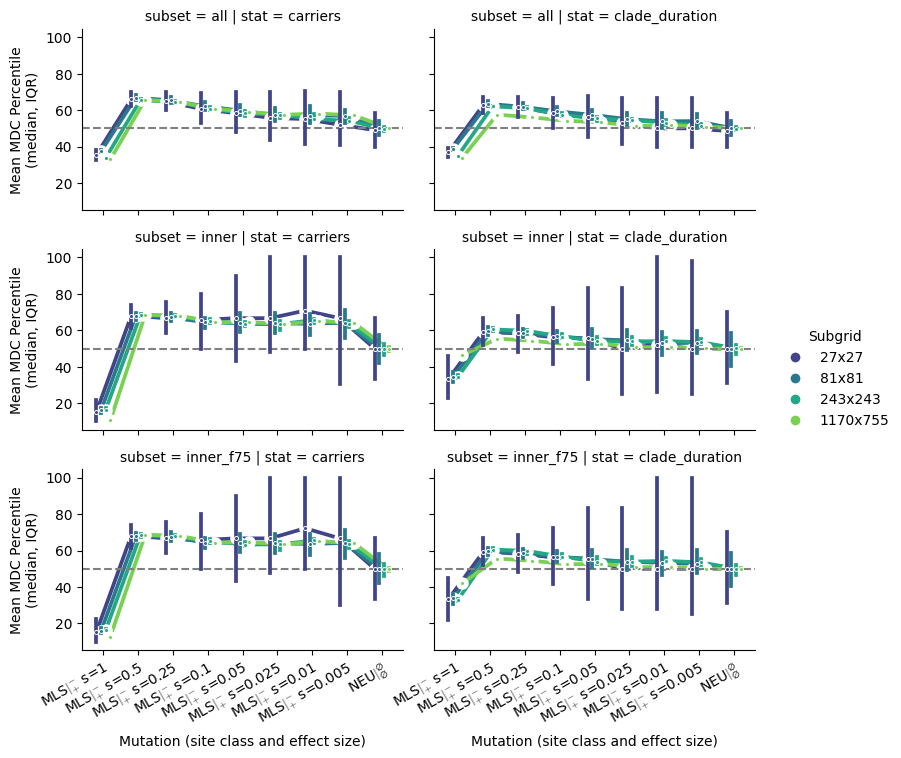

In [ ]:
with tp.teed(
    sns.catplot,
    data=fitness_detection[
        fitness_detection["normalization"] == "epoch100"
    ].dropna(subset=["site_mean_pct"]),
    x="mutation",
    y="site_mean_pct",
    order=mutation_order,
    hue="pop_size",
    hue_order=pop_size_order,
    palette="viridis",
    col="stat",
    row="subset",
    kind="point",
    estimator="median",
    errorbar=("pi", 50),
    dodge=0.4,
    height=2.4,
    aspect=1.6,
    teeplot_outattrs={"normalization": "epoch100"},
    teeplot_outexclude=["palette", "hue_order", "dodge", "order"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    gap_points(*_g.axes.flat, _g.legend)
    _g.refline(y=50, color="gray", linestyle="--")
    _g.set_axis_labels(
        "Mutation (site class and effect size)",
        "Mean MDC Percentile\n(median, IQR)",
    )
    for _a in _g.axes.flat:
        plt.setp(
            _a.get_xticklabels(),
            rotation=30,
            ha="right",
            rotation_mode="anchor",
        )
    _g.legend.set_title("Subgrid")

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=stat+hue=pop-size+kind=point+normalization=all+row=subset+viz=catplot+x=mutation+y=detected+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=stat+hue=pop-size+kind=point+normalization=all+row=subset+viz=catplot+x=mutation+y=detected+ext=.png


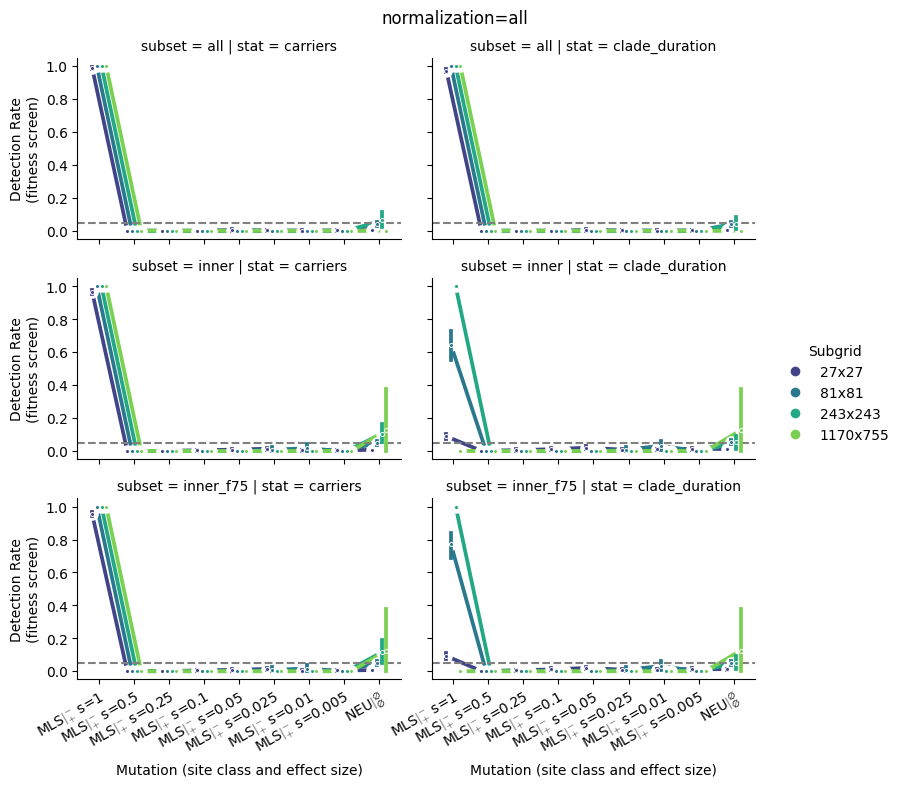

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=stat+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=detected+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=stat+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=detected+ext=.png


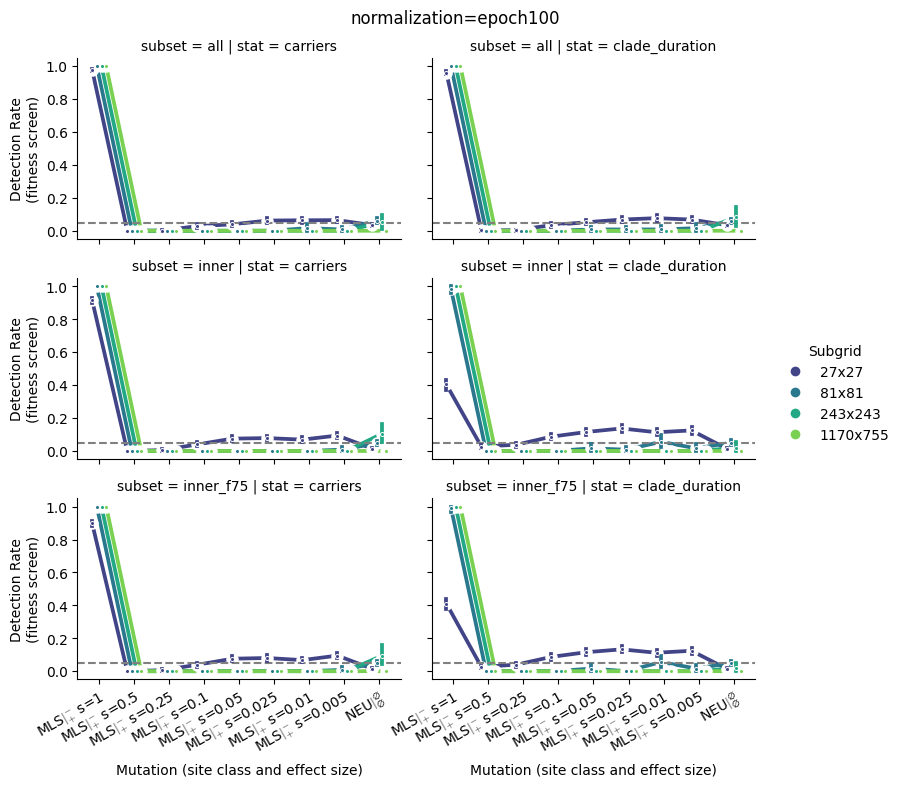

In [ ]:
for _norm in "all", "epoch100":
    with tp.teed(
        sns.catplot,
        data=fitness_detection[
            fitness_detection["normalization"] == _norm
        ].astype({"detected": float}),
        x="mutation",
        y="detected",
        order=mutation_order,
        hue="pop_size",
        hue_order=pop_size_order,
        palette="viridis",
        col="stat",
        row="subset",
        kind="point",
        errorbar=("ci", 95),
        n_boot=1000,
        seed=SEED,
        dodge=0.4,
        height=2.4,
        aspect=1.6,
        teeplot_outattrs={"normalization": _norm},
        teeplot_outexclude=[
            "palette",
            "hue_order",
            "dodge",
            "order",
            "seed",
        ],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        gap_points(*_g.axes.flat, _g.legend)
        _g.refline(y=ALPHA, color="gray", linestyle="--")
        _g.set(ylim=(-0.05, 1.05))
        _g.set_axis_labels(
            "Mutation (site class and effect size)",
            "Detection Rate\n(fitness screen)",
        )
        for _a in _g.axes.flat:
            plt.setp(
                _a.get_xticklabels(),
                rotation=30,
                ha="right",
                rotation_mode="anchor",
            )
        _g.legend.set_title("Subgrid")
        _g.figure.suptitle(f"normalization={_norm}", y=1.02)
    plt.close("all")

In [ ]:
mo.md(f"""
## Detectability Summary

Fraction of populations in which each screen detects each site at $\\alpha = {ALPHA}$, by population size (rows) and effect size (columns).
The NEU column gives the false positive rate over neutral control sites, and should sit near {ALPHA}.
Fitness screens shown use `epoch100` normalization.

Note that sampled fossil genomes per population grow with subgrid size (fossils were sampled with an equal budget per subgrid), so population size and sample size are confounded here.
""")

## Detectability Summary

Fraction of populations in which each screen detects each site at $\alpha = 0.05$, by population size (rows) and effect size (columns).
The NEU column gives the false positive rate over neutral control sites, and should sit near 0.05.
Fitness screens shown use `epoch100` normalization.

Note that sampled fossil genomes per population grow with subgrid size (fossils were sampled with an equal budget per subgrid), so population size and sample size are confounded here.

In [ ]:
_screens = {
    "frequency": freq_screen,
    **{
        f"fitness {_stat} {_subset}": fitness_detection[
            (fitness_detection["normalization"] == "epoch100")
            & (fitness_detection["stat"] == _stat)
            & (fitness_detection["subset"] == _subset)
        ]
        for _stat in ("carriers", "clade_duration")
        for _subset in ("all", "inner_f75")
    },
}
detectability = pd.concat(
    [
        _df.groupby(["pop_size", "mutation"], as_index=False)
        .agg(
            detection_rate=("detected", "mean"),
            num_screened=("detected", "size"),
        )
        .assign(screen=_screen)
        for _screen, _df in _screens.items()
    ],
    ignore_index=True,
)
detectability.pivot_table(
    index=["screen", "pop_size"],
    columns="mutation",
    values="detection_rate",
    sort=False,
)

mutation MLS$|^{-}_{+}$ s=0.005 MLS$|^{-}_{+}$ s=0.01 MLS$|^{-}_{+}$ s=0.025 MLS$|^{-}_{+}$ s=0.05 MLS$|^{-}_{+}$ s=0.1 MLS$|^{-}_{+}$ s=0.25 MLS$|^{-}_{+}$ s=0.5 MLS$|^{-}_{+}$ s=1 NEU$|^{\varnothing}_{\varnothing}$ screen pop_size frequency 1170x755 1.000000 1.000000 1.000000 1.000000 1.000000 1.000000 1.00000 1.000000 0.000000 243x243 0.916667 1.000000 1.000000 1.000000 1.000000 1.000000 1.00000 1.000000 0.093750 27x27 0.053402 0.079242 0.184324 0.437554 0.910422 1.000000 1.00000 1.000000 0.033376 81x81 0.277778 0.293651 0.793651 0.992063 1.000000 1.000000 1.00000 1.000000 0.047619 fitness carriers all 1170x755 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.00000 1.000000 0.000000 ... ... ... ... ... ... ... ... ... ... ... fitness clade_duration all 81x81 0.015873 0.007937 0.007937 0.007937 0.000000 0.000000 0.00000 1.000000 0.059524 fitness clade_duration inner_f75 1170x755 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.00000 1.000000 0.000000 243x243 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.00000 1.000000 0.020833 27x27 0.124031 0.111972 0.132644 0.115418 0.086994 0.039621 0.02584 0.410853 0.014643 81x81 0.015873 0.055556 0.000000 0.015873 0.000000 0.000000 0.00000 0.992063 0.050595 20 rows × 9 columns

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/screen=frequency+viz=heatmap+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/screen=frequency+viz=heatmap+ext=.png


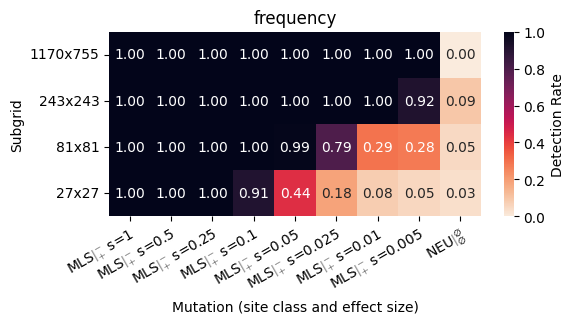

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/screen=fitness-carriers-all+viz=heatmap+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/screen=fitness-carriers-all+viz=heatmap+ext=.png


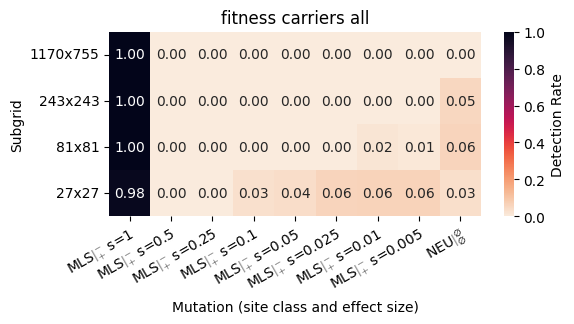

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/screen=fitness-carriers-inner_f75+viz=heatmap+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/screen=fitness-carriers-inner_f75+viz=heatmap+ext=.png


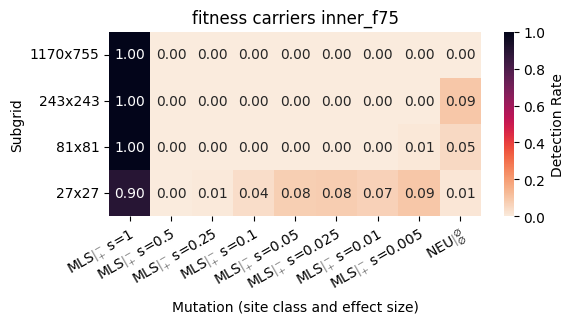

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/screen=fitness-clade_duration-all+viz=heatmap+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/screen=fitness-clade_duration-all+viz=heatmap+ext=.png


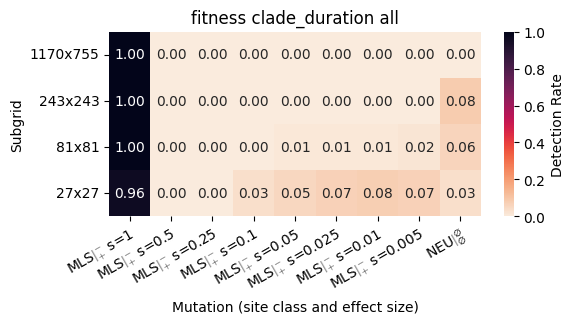

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/screen=fitness-clade_duration-inner_f75+viz=heatmap+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/screen=fitness-clade_duration-inner_f75+viz=heatmap+ext=.png


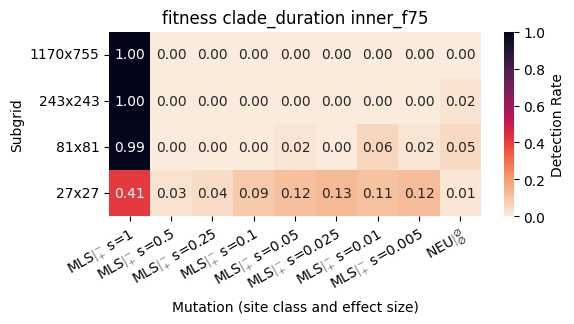

In [ ]:
for _screen, _df in detectability.groupby("screen", sort=False):
    _pivot = _df.pivot(
        index="pop_size", columns="mutation", values="detection_rate"
    ).reindex(index=pop_size_order[::-1], columns=mutation_order)
    with tp.teed(
        sns.heatmap,
        _pivot,
        annot=True,
        fmt=".2f",
        cmap="rocket_r",
        vmin=0,
        vmax=1,
        cbar_kws={"label": "Detection Rate"},
        teeplot_outattrs={"screen": _screen.replace(" ", "-")},
        teeplot_outexclude=["annot", "fmt", "cmap", "vmin", "vmax"],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _ax:
        _ax.set_xlabel("Mutation (site class and effect size)")
        _ax.set_ylabel("Subgrid")
        _ax.set_title(_screen)
        plt.setp(
            _ax.get_xticklabels(),
            rotation=30,
            ha="right",
            rotation_mode="anchor",
        )
        _ax.tick_params(axis="y", rotation=0)
        _ax.figure.set_size_inches(6, 2.4)
    plt.close("all")

In [ ]:
mo.md(f"""
## Detectability by Site Class

The same screen results, recast with effect size on the x axis, site class as color, and subgrid size as columns.
Neutral control sites appear as their own x position.
Error bars are 95% bootstrap confidence intervals over populations; the dashed line marks $\\alpha = {ALPHA}$.
Fitness screens shown use `epoch100` normalization.
""")

## Detectability by Site Class

The same screen results, recast with effect size on the x axis, site class as color, and subgrid size as columns.
Neutral control sites appear as their own x position.
Error bars are 95% bootstrap confidence intervals over populations; the dashed line marks $\alpha = 0.05$.
Fitness screens shown use `epoch100` normalization.

In [ ]:
def _split_mutation(df):
    _parts = df["mutation"].str.extract(r"^(.+) s=(\S+)$")
    return df.assign(
        kind=_parts[0].fillna(kind_labels["NEU"]),
        effect_size=_parts[1].fillna("neu").map(effect_pct),
    )

by_kind = pd.concat(
    [
        freq_screen.assign(
            screen="frequency", p_value=freq_screen["poisson_sf_p"]
        ),
        *(
            fitness_detection[
                (fitness_detection["normalization"] == "epoch100")
                & (fitness_detection["stat"] == _stat)
                & (fitness_detection["subset"] == _subset)
            ].assign(
                screen=f"fitness {_stat} {_subset}",
                p_value=lambda df: df["p_mw_less"],
            )
            for _stat in ("carriers", "clade_duration")
            for _subset in ("all", "inner_f75")
        ),
    ],
    ignore_index=True,
)[
    [
        "screen",
        "pop_code",
        "pop_size",
        "site",
        "mutation",
        "detected",
        "site_mean_pct",
        "p_value",
    ]
].pipe(
    _split_mutation
)
kind_order = [
    kind_labels[_kind]
    for _kind in ("NEU", "BENwg", "DELbg", "MLS")
    if kind_labels[_kind] in set(by_kind["kind"])
]
effect_size_order = ["neu"] + sorted(
    set(by_kind["effect_size"]) - {"neu"}, key=float
)
kind_palette = {
    kind_labels[_kind]: ETI_PALETTE[_key][1]
    for _kind, _key in (
        ("NEU", "neutral"),
        ("BENwg", "BENwg"),
        ("DELbg", "DELbg"),
        ("MLS", "MLS"),
    )
}
freq_by_kind = freq_screen.pipe(_split_mutation)
by_kind.groupby(["screen", "pop_size", "kind", "effect_size"], sort=False)[
    "detected"
].mean().unstack("pop_size")

pop_size 1170x755 27x27 81x81 243x243 screen kind effect_size frequency MLS$|^{-}_{+}$ 100 1.0 1.000000 1.000000 1.000000 50 1.0 1.000000 1.000000 1.000000 25 1.0 1.000000 1.000000 1.000000 10 1.0 0.910422 1.000000 1.000000 5 1.0 0.437554 0.992063 1.000000 ... ... ... ... ... ... ... fitness clade_duration inner_f75 MLS$|^{-}_{+}$ 5 0.0 0.115418 0.015873 0.000000 2.5 0.0 0.132644 0.000000 0.000000 1 0.0 0.111972 0.055556 0.000000 0.5 0.0 0.124031 0.015873 0.000000 NEU$|^{\varnothing}_{\varnothing}$ neu 0.0 0.014643 0.050595 0.020833 45 rows × 4 columns

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=frequency+viz=catplot+x=effect-size+y=detected+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=frequency+viz=catplot+x=effect-size+y=detected+ext=.png


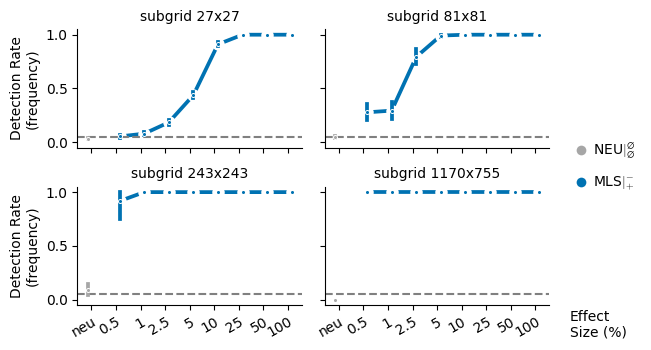

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-carriers-all+viz=catplot+x=effect-size+y=detected+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-carriers-all+viz=catplot+x=effect-size+y=detected+ext=.png


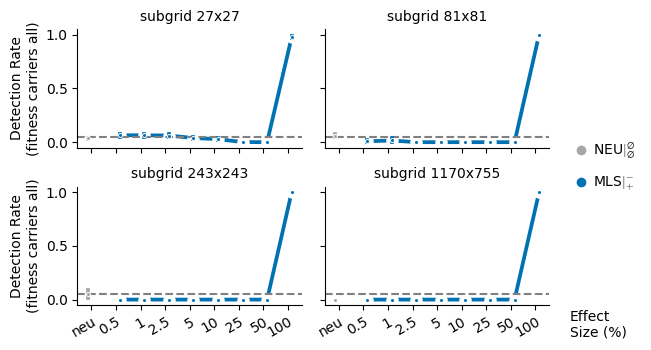

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-carriers-inner_f75+viz=catplot+x=effect-size+y=detected+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-carriers-inner_f75+viz=catplot+x=effect-size+y=detected+ext=.png


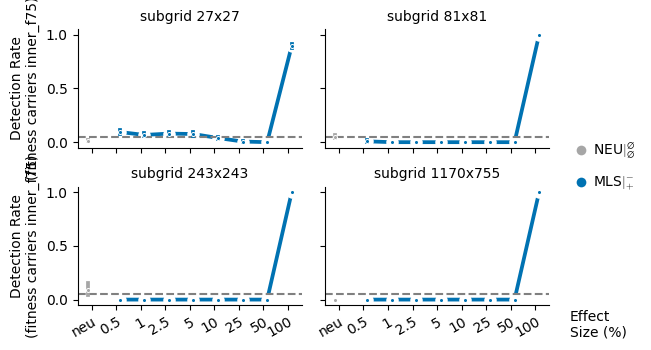

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-clade_duration-all+viz=catplot+x=effect-size+y=detected+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-clade_duration-all+viz=catplot+x=effect-size+y=detected+ext=.png


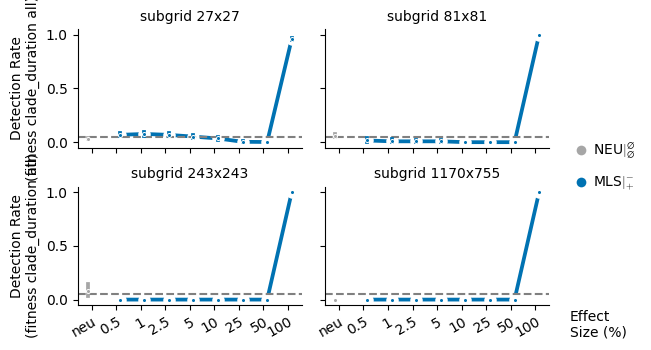

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-clade_duration-inner_f75+viz=catplot+x=effect-size+y=detected+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+hue=kind+kind=point+screen=fitness-clade_duration-inner_f75+viz=catplot+x=effect-size+y=detected+ext=.png


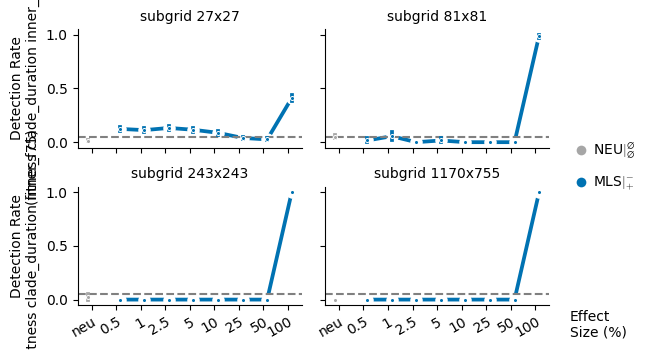

In [ ]:
for _screen, _df in by_kind.groupby("screen", sort=False):
    with tp.teed(
        sns.catplot,
        data=_df.astype({"detected": float}),
        x="effect_size",
        y="detected",
        order=effect_size_order,
        hue="kind",
        hue_order=kind_order,
        palette=kind_palette,
        col="pop_size",
        col_order=pop_size_order,
        col_wrap=2,
        kind="point",
        errorbar=("ci", 95),
        n_boot=1000,
        seed=SEED,
        dodge=0.3,
        height=1.8,
        aspect=1.6,
        teeplot_outattrs={"screen": _screen.replace(" ", "-")},
        teeplot_outexclude=[
            "palette",
            "hue_order",
            "col_order",
            "col_wrap",
            "dodge",
            "order",
            "seed",
        ],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        gap_points(*_g.axes.flat, _g.legend)
        _g.refline(y=ALPHA, color="gray", linestyle="--")
        _g.set(ylim=(-0.05, 1.05))
        _g.set_axis_labels("", f"Detection Rate\n({_screen})")
        _g.set_titles(col_template="subgrid {col_name}")
        for _a in _g.axes.flat:
            plt.setp(
                _a.get_xticklabels(),
                rotation=30,
                ha="right",
                rotation_mode="anchor",
            )
        corner_xlabel(_g, right_legend(_g))
    plt.close("all")

## MDC Size and Duration by Site Class

The fitness screen's underlying measurement: each site's mean MDC percentile for clade size (`carriers`) and clade duration, ranked against background (neutral) MDCs within the same population and 100-update origin epoch.
All MDCs are included.
The dashed line at 50 marks parity with background; lower values mean smaller or shorter-lived clades.
Points are medians over populations, with error bars spanning the interquartile range.

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-carriers-all+viz=catplot+x=effect-size+y=site-mean-pct+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-carriers-all+viz=catplot+x=effect-size+y=site-mean-pct+ext=.png


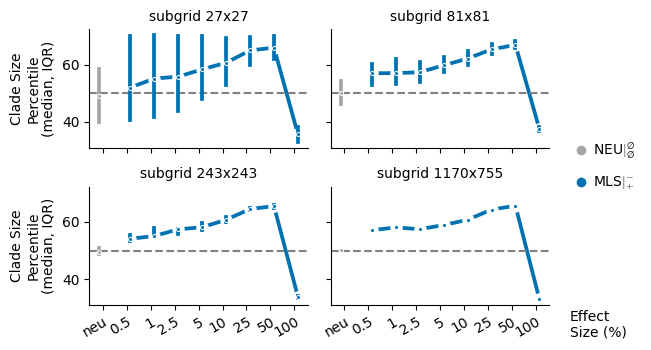

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-clade_duration-all+viz=catplot+x=effect-size+y=site-mean-pct+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-clade_duration-all+viz=catplot+x=effect-size+y=site-mean-pct+ext=.png


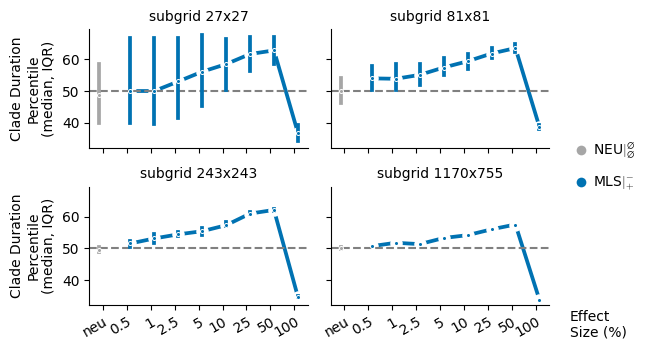

In [ ]:
_stat_names = {
    "carriers": "Clade Size",
    "clade_duration": "Clade Duration",
}
# all MDCs subset only
_fitness = by_kind[
    by_kind["screen"].str.startswith("fitness ")
    & by_kind["screen"].str.endswith(" all")
]
for _screen, _df in _fitness.groupby("screen", sort=False):
    _stat = _screen.split(" ")[1]
    with tp.teed(
        sns.catplot,
        data=_df.dropna(subset=["site_mean_pct"]),
        x="effect_size",
        y="site_mean_pct",
        order=effect_size_order,
        hue="kind",
        hue_order=kind_order,
        palette=kind_palette,
        col="pop_size",
        col_order=pop_size_order,
        col_wrap=2,
        kind="point",
        estimator="median",
        errorbar=("pi", 50),
        dodge=0.3,
        height=1.8,
        aspect=1.6,
        teeplot_outattrs={"screen": _screen.replace(" ", "-")},
        teeplot_outexclude=[
            "palette",
            "hue_order",
            "col_order",
            "col_wrap",
            "dodge",
            "order",
        ],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        gap_points(*_g.axes.flat, _g.legend)
        _g.refline(y=50, color="gray", linestyle="--")
        _g.set_axis_labels(
            "",
            f"{_stat_names[_stat]}\nPercentile\n(median, IQR)",
        )
        _g.set_titles(col_template="subgrid {col_name}")
        for _a in _g.axes.flat:
            plt.setp(
                _a.get_xticklabels(),
                rotation=30,
                ha="right",
                rotation_mode="anchor",
            )
        corner_xlabel(_g, right_legend(_g))
    plt.close("all")

In [ ]:
mo.md(f"""
## Detection Strength by Site Class

Screen p-values on a log scale, descending from $p = 1$ at top so stronger evidence plots lower.
Points are medians over populations, with error bars spanning the interquartile range; the dashed line marks $\\alpha = {ALPHA}$.
Populations where a site produced no MDCs (so the screen could not run) count as $p = 1$, and p-values below $10^{{-9}}$ are clipped to $10^{{-9}}$.
Fitness screens shown use all MDCs and `epoch100` normalization.
""")

## Detection Strength by Site Class

Screen p-values on a log scale, descending from $p = 1$ at top so stronger evidence plots lower.
Points are medians over populations, with error bars spanning the interquartile range; the dashed line marks $\alpha = 0.05$.
Populations where a site produced no MDCs (so the screen could not run) count as $p = 1$, and p-values below $10^{-9}$ are clipped to $10^{-9}$.
Fitness screens shown use all MDCs and `epoch100` normalization.

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=frequency+viz=catplot+x=effect-size+y=p-value+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=frequency+viz=catplot+x=effect-size+y=p-value+ext=.png


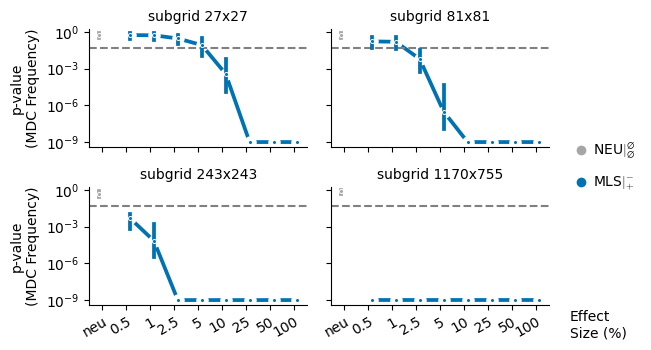

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-carriers-all+viz=catplot+x=effect-size+y=p-value+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-carriers-all+viz=catplot+x=effect-size+y=p-value+ext=.png


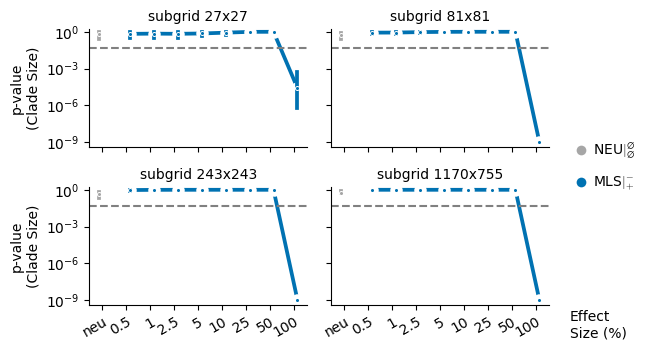

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-clade_duration-all+viz=catplot+x=effect-size+y=p-value+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+screen=fitness-clade_duration-all+viz=catplot+x=effect-size+y=p-value+ext=.png


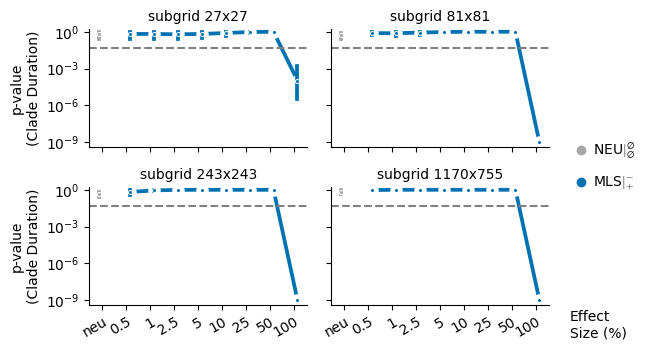

In [ ]:
_screen_names = {
    "frequency": "MDC Frequency",
    "fitness carriers all": "Clade Size",
    "fitness clade_duration all": "Clade Duration",
}
for _screen, _name in _screen_names.items():
    _df = by_kind[by_kind["screen"] == _screen].assign(
        p_value=lambda df: df["p_value"].fillna(1.0).clip(lower=1e-9),
    )
    with tp.teed(
        sns.catplot,
        data=_df,
        x="effect_size",
        y="p_value",
        order=effect_size_order,
        hue="kind",
        hue_order=kind_order,
        palette=kind_palette,
        col="pop_size",
        col_order=pop_size_order,
        col_wrap=2,
        kind="point",
        estimator="median",
        errorbar=("pi", 50),
        dodge=0.3,
        height=1.8,
        aspect=1.6,
        log_scale=(False, True),
        teeplot_outattrs={"screen": _screen.replace(" ", "-")},
        teeplot_outexclude=[
            "palette",
            "hue_order",
            "col_order",
            "col_wrap",
            "dodge",
            "order",
            "log_scale",
        ],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        gap_points(*_g.axes.flat, _g.legend)
        _g.refline(y=ALPHA, color="gray", linestyle="--")
        # p = 1 at top, descending to the 1e-9 clip floor, with a
        # little padding so edge markers aren't cut off
        _g.set(
            ylim=(10**-9.4, 10**0.2),
            yticks=[1, 1e-3, 1e-6, 1e-9],
        )
        _g.set_axis_labels("", f"p-value\n({_name})")
        _g.set_titles(col_template="subgrid {col_name}")
        for _a in _g.axes.flat:
            plt.setp(
                _a.get_xticklabels(),
                rotation=30,
                ha="right",
                rotation_mode="anchor",
            )
        corner_xlabel(_g, right_legend(_g))
    plt.close("all")

teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+viz=catplot+x=effect-size+y=fold-enrichment+ext=.pdf
teeplots/2026-10-18-mls-spectrum-subgrid-fossils/col=pop-size+estimator=median+hue=kind+kind=point+viz=catplot+x=effect-size+y=fold-enrichment+ext=.png


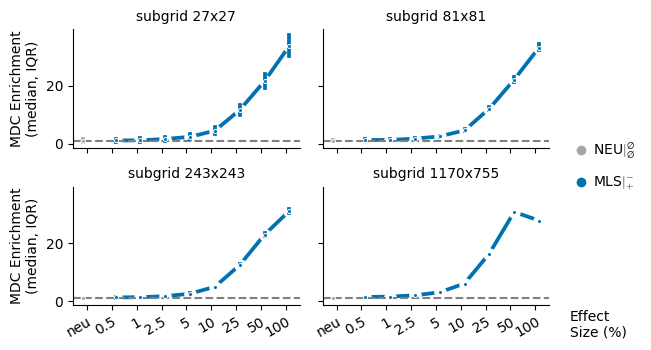

In [ ]:
with tp.teed(
    sns.catplot,
    data=freq_by_kind,
    x="effect_size",
    y="fold_enrichment",
    order=effect_size_order,
    hue="kind",
    hue_order=kind_order,
    palette=kind_palette,
    col="pop_size",
    col_order=pop_size_order,
    col_wrap=2,
    kind="point",
    estimator="median",
    errorbar=("pi", 50),
    dodge=0.3,
    height=1.8,
    aspect=1.6,
    teeplot_outexclude=[
        "palette",
        "hue_order",
        "col_order",
        "col_wrap",
        "dodge",
        "order",
    ],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    gap_points(*_g.axes.flat, _g.legend)
    _g.refline(y=1, color="gray", linestyle="--")
    _g.set_axis_labels("", "MDC Enrichment\n(median, IQR)")
    _g.set_titles(col_template="subgrid {col_name}")
    for _a in _g.axes.flat:
        plt.setp(
            _a.get_xticklabels(),
            rotation=30,
            ha="right",
            rotation_mode="anchor",
        )
    corner_xlabel(_g, right_legend(_g))
plt.close("all")